In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [34]:
main_df = pd.read_csv(r"C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\SP500.csv")


main_df["diff"] = main_df["SP500"].diff(1)
main_df = main_df.dropna()
print(main_df.columns)
                  

Index(['observation_date', 'SP500', 'diff'], dtype='str')


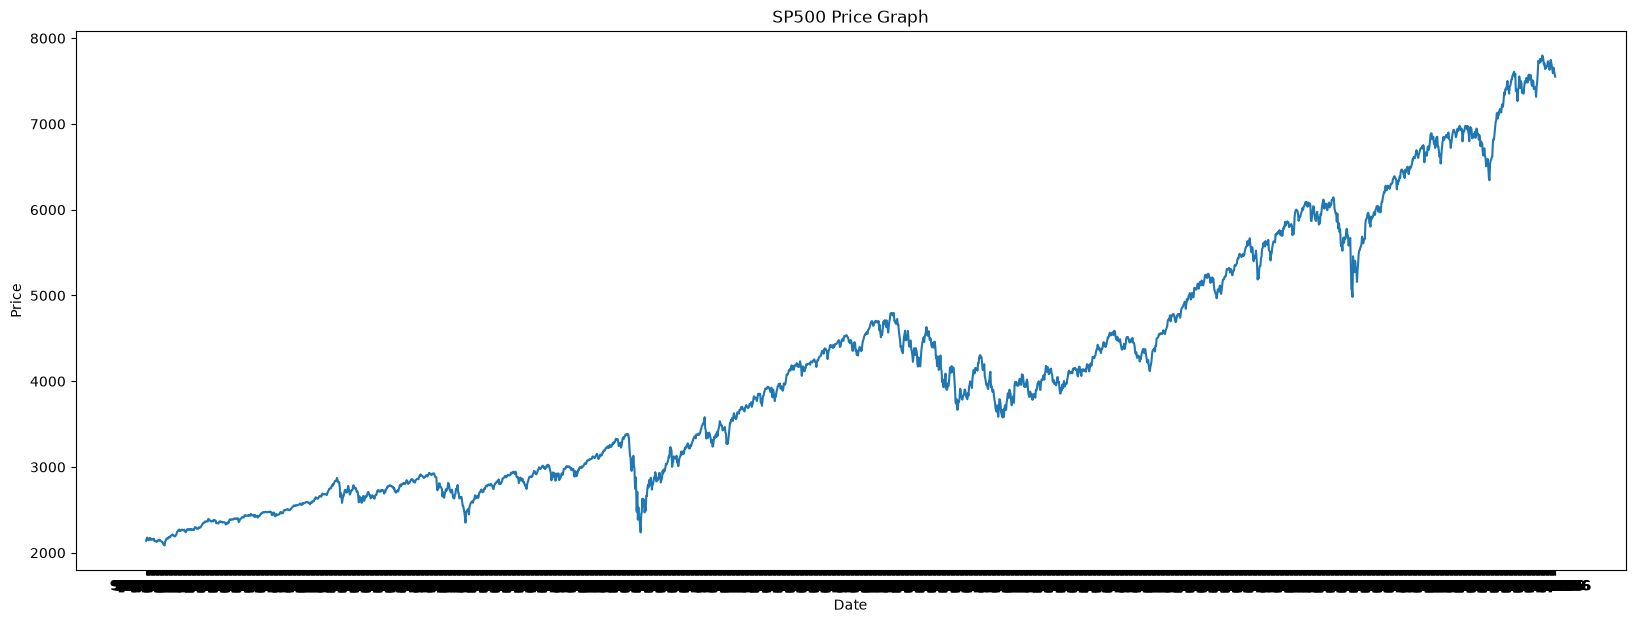

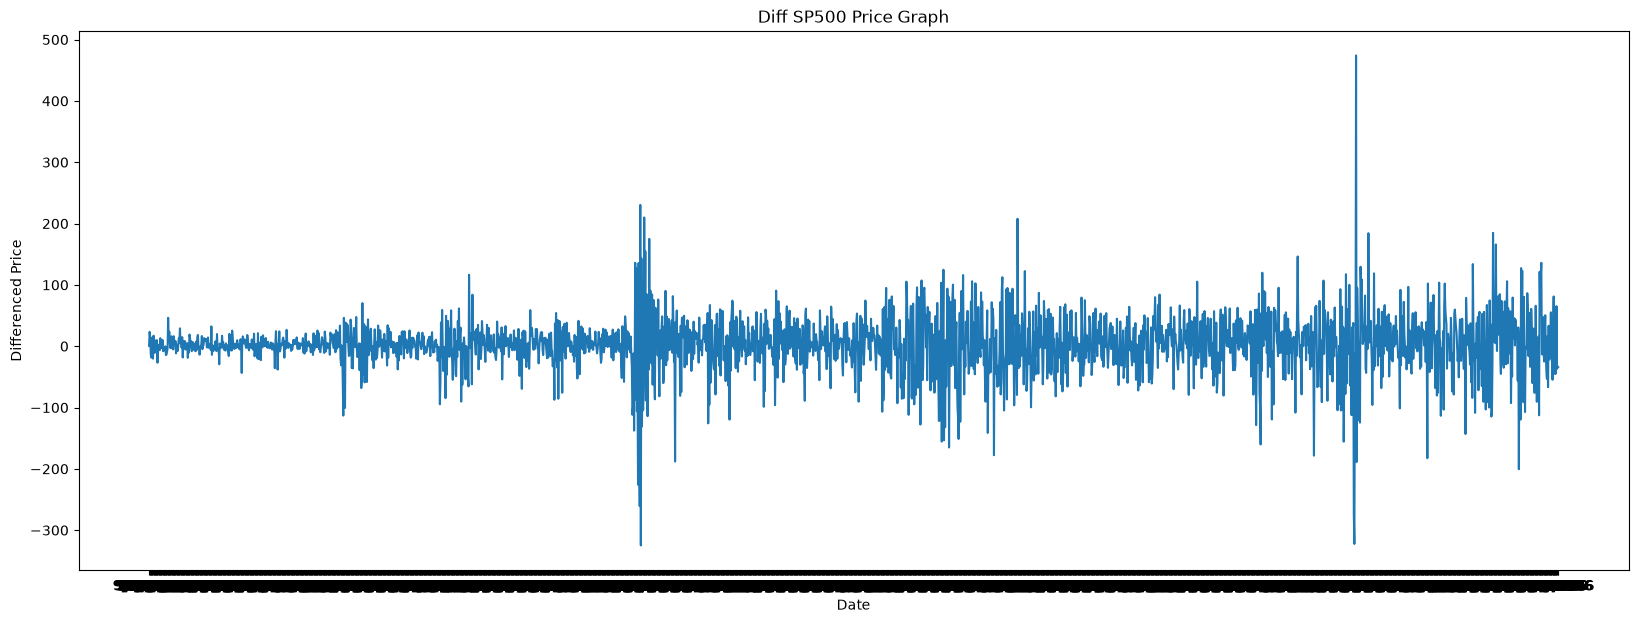

In [33]:
fig, ax = plt.subplots(figsize=(20,7))
ax.plot(main_df["observation_date"], main_df["SP500"], label = "SP500 price index")
ax.set_title("SP500 Price Graph")
ax.set_xlabel("Date")
ax.set_ylabel("Price")

fig, ax = plt.subplots(figsize=(20,7))
ax.plot(main_df["observation_date"], main_df["diff"], label = "Differenced SP500 price index")
ax.set_title("Diff SP500 Price Graph")
ax.set_xlabel("Date")
ax.set_ylabel("Differenced Price")


plt.show()

In [22]:
auto_arima(main_df["SP500"], m = 12, trace = True).summary()

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=26206.455, Time=5.42 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=26245.787, Time=0.05 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=26234.304, Time=0.36 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=26235.505, Time=0.95 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=26249.545, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=26205.605, Time=3.77 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=26203.660, Time=1.81 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=26205.604, Time=5.34 sec
 ARIMA(1,1,2)(0,0,0)[12] intercept   : AIC=26230.717, Time=1.02 sec
 ARIMA(2,1,1)(0,0,0)[12] intercept   : AIC=26234.241, Time=0.91 sec
 ARIMA(3,1,2)(0,0,0)[12] intercept   : AIC=26228.428, Time=1.38 sec
 ARIMA(2,1,3)(0,0,0)[12] intercept   : AIC=26227.479, Time=1.24 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=26230.120, Time=0.61 sec
 ARIMA(1,1,3)(0,0,0)[12] intercept   : AIC=26225.701, Time=1.56 sec
 ARIM

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 2512
Model:               SARIMAX(2, 1, 2)   Log Likelihood              -13095.830
Date:                Thu, 17 Sep 2026   AIC                          26203.660
Time:                        10:39:08   BIC                          26238.630
Sample:                             0   HQIC                         26216.353
                               - 2512                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      7.4464      3.086      2.413      0.016       1.398      13.495
ar.L1         -1.7213      0.033    -52.950      0.000      -1.785      -1.658
ar.L2         -0.8562      0.032    -26.622      0.000      -0.919      -0.793
ma.L1          1.6546      0.038     43.582      0.000       1.580       1.729
ma.L2          0.7823      0.038     20.739      0.000       0.708       0.856
sigma2      1976.2305     24.883     79.421      0.000    1927.461    2025.000
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):              8579.89
Prob(Q):                              0.88   Prob(JB):                         0.00
Heteroskedasticity (H):               6.38   Skew:                            -0.30
Prob(H) (two-sided):                  0.00   Kurtosis:                        12.04
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [35]:
def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary')

check_stationarity(main_df["diff"])

ADF Statistic: -15.80785479759562
p-value: 1.0552625587598991e-28
Stationary


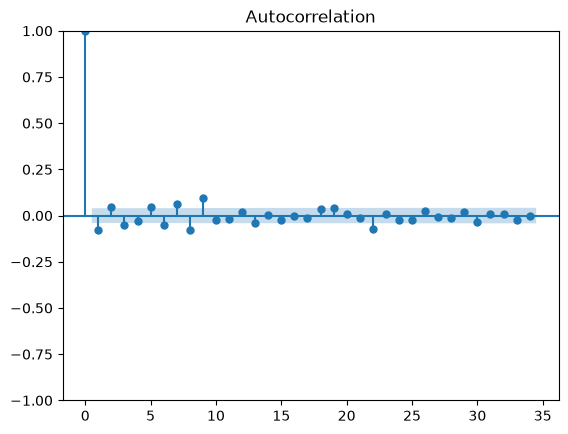

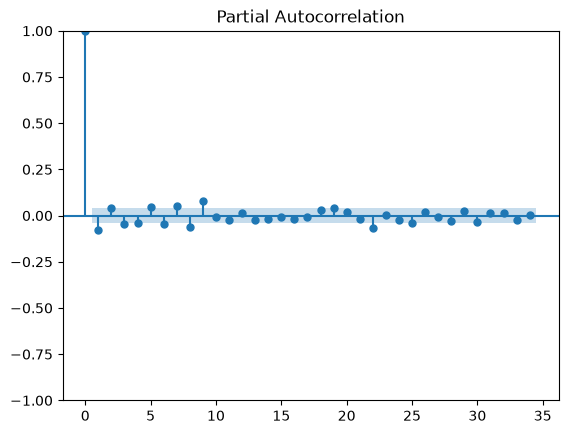

In [36]:
training = np.asarray(main_df["diff"])
plot_acf(training)
plot_pacf(training)
plt.show()